# Inside the models: filters and feature maps

This notebook looks at what the two trained models respond to, using the figures generated by `src/visualize.py`:

- **SimpleCNN**: 30 epochs, 64 px input, trained from scratch
- **ResNet18**: 15 epochs, 128 px input, pretrained on ImageNet and fine-tuned

Both models are looked at on the same EuroSAT test patches. The figures are saved in `results/visualizations/`; the cell below generates any that are missing (this needs the trained checkpoints in `checkpoints/`).

These are qualitative observations on a handful of patches. They show what the networks respond to, not why they decide the way they do.

In [4]:
import os
import subprocess
import sys
from pathlib import Path

from IPython.display import display
from PIL import Image

# Run from the project root so that relative paths (data/, checkpoints/) work.
if Path.cwd().name == "notebooks":
    os.chdir("..")

FIGS = Path("results/visualizations")

# Each command of src/visualize.py and the figures it produces.
COMMANDS = {
    "first-layer": [
        "first_layer_cnn_e30.png",
        "first_layer_resnet18_e15.png",
        "resnet_filter_change.png",
    ],
    "samples": ["samples_overview.png"],
    "feature-maps": [
        f"feature_maps_{run}_{role}.png"
        for run in ("cnn_e30", "resnet18_e15")
        for role in ("forest", "highway", "cnn_wrong_1")
    ],
}

# Generate only what is missing.
for command, files in COMMANDS.items():
    if not all((FIGS / name).exists() for name in files):
        print(f"Running: python src/visualize.py {command}")
        subprocess.run([sys.executable, "src/visualize.py", command], check=True)


def show(name: str, width: int = 1000) -> None:
    """Display a saved figure, downscaled so the notebook file stays small."""
    image = Image.open(FIGS / name)
    height = round(image.height * width / image.width)
    display(image.resize((width, height), Image.LANCZOS))

## 1. Selected test patches

Seven test patches: one each of `Forest`, `River`, `Highway`, `AnnualCrop` and `PermanentCrop` that both models classify correctly, plus the first two patches that SimpleCNN gets wrong and ResNet18 gets right. Red titles mark errors.

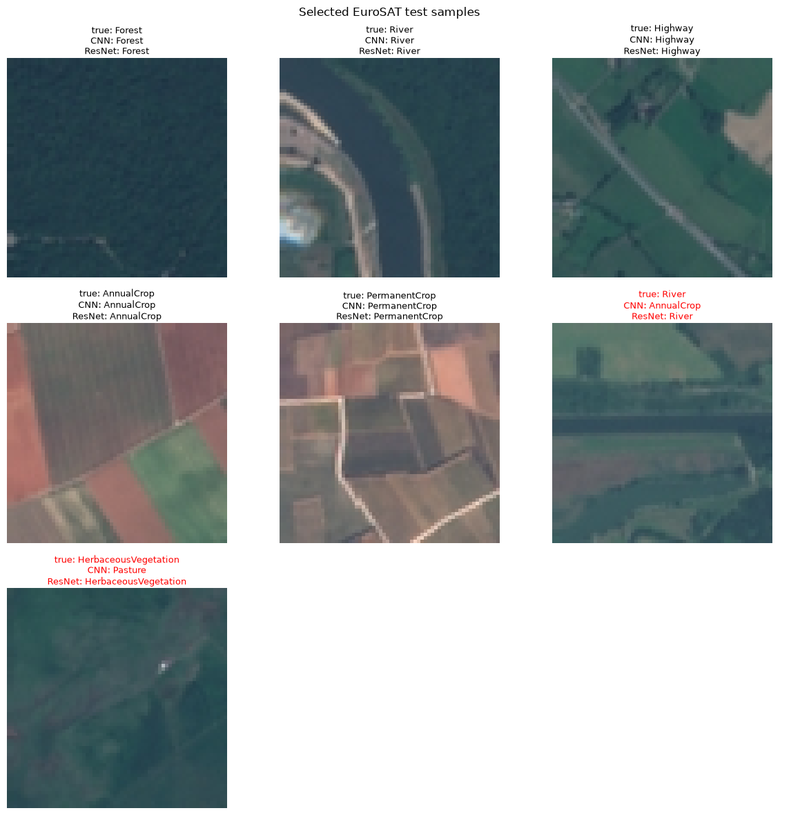

In [3]:
show("samples_overview.png", width=800)

The two SimpleCNN errors are a `River` patch predicted as `AnnualCrop` (a narrow dark channel crossing agricultural fields) and a low-contrast `HerbaceousVegetation` patch predicted as `Pasture`.

## 2. First-layer filters

The first convolutional layer is the only one whose weights can be shown directly as small RGB images, because it has three input channels. Deeper filters have dozens of input channels and cannot be displayed this way.

### SimpleCNN (32 filters, 3 x 3)

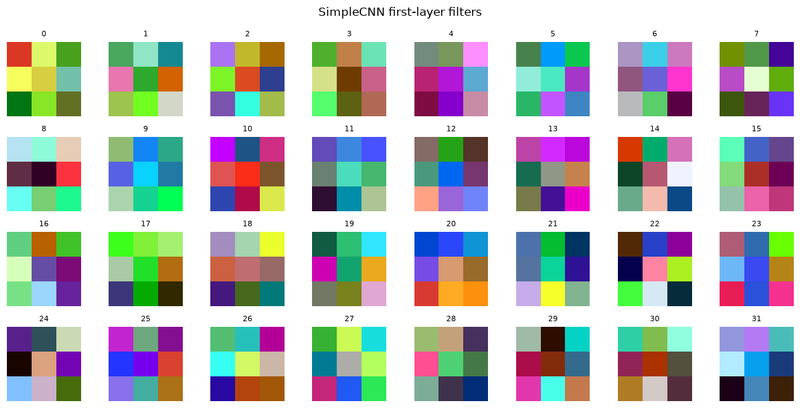

In [5]:
show("first_layer_cnn_e30.png", width=800)

The filters look like patches of saturated colors, with no obvious spatial structure such as oriented edges. Two caveats:

- The figure rescales every filter independently to [0, 1], which exaggerates small weights. A gray-centered normalization (zero weights shown as gray) gave the same impression, so only the min-max version is kept here.
- A 3 x 3 filter is very small, so patterns are hard to see by eye.

The weights alone are therefore not very informative. The feature maps in section 3 show that the first block does respond to boundaries (roads, field borders, a canal), even though the filters do not look like edge detectors.

### ResNet18 (64 filters, 7 x 7)

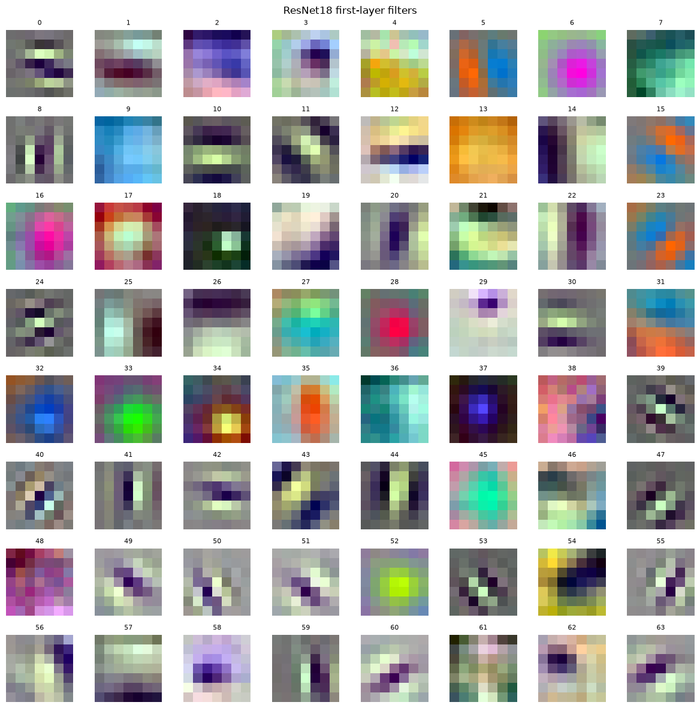

In [6]:
show("first_layer_resnet18_e15.png", width=700)

The filters look like a typical ImageNet first layer:

- oriented edge detectors on a gray background (for example filters 41 and 44),
- color blobs (for example 9, 13, 28, 33 and 52),
- pairs of opposing colors (for example 5, 15 and 23).

Fine-tuning used a small learning rate, so this is mostly what the model inherited from ImageNet, as the next plot shows.

### How much did fine-tuning change the ResNet18 first layer?

For each filter, the relative change between the fine-tuned and the original ImageNet weights.

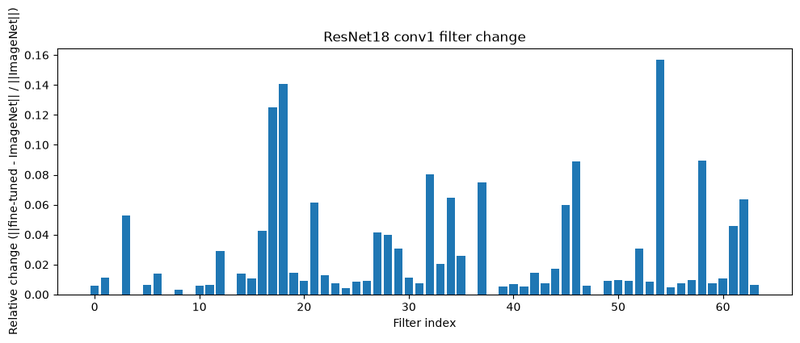

In [7]:
show("resnet_filter_change.png", width=800)

Most filters moved by less than about 3%. A few moved much more: filter 54 (about 16%), 18 (about 14%) and 17 (about 12%). Several of the larger changes are in strongly colored filters (for example 17 and 54), so the adaptation may partly concern color statistics, since satellite images differ from ImageNet photos. This was not tested, and a large relative change does not mean a filter matters more for the prediction.

## 3. Feature maps

Each figure runs one patch through one model and shows the activations after each stage.

How to read them:

- **Rows** are layers, with the shape (channels x height x width) written on the left. For SimpleCNN the maps are taken after the ReLU of each block, before pooling. For ResNet18 they are taken after the stem and after each of the four residual stages.
- **Column 0** is the mean over all channels. **Columns 1 to 8** are the eight channels with the highest mean activation for that patch, so the displayed channels differ between patches and models.
- **Every map is rescaled independently** to its own minimum and maximum, so colors cannot be compared between maps, only the spatial pattern inside each one.

### 3.1 Highway patch: a diagonal road across fields

SimpleCNN:

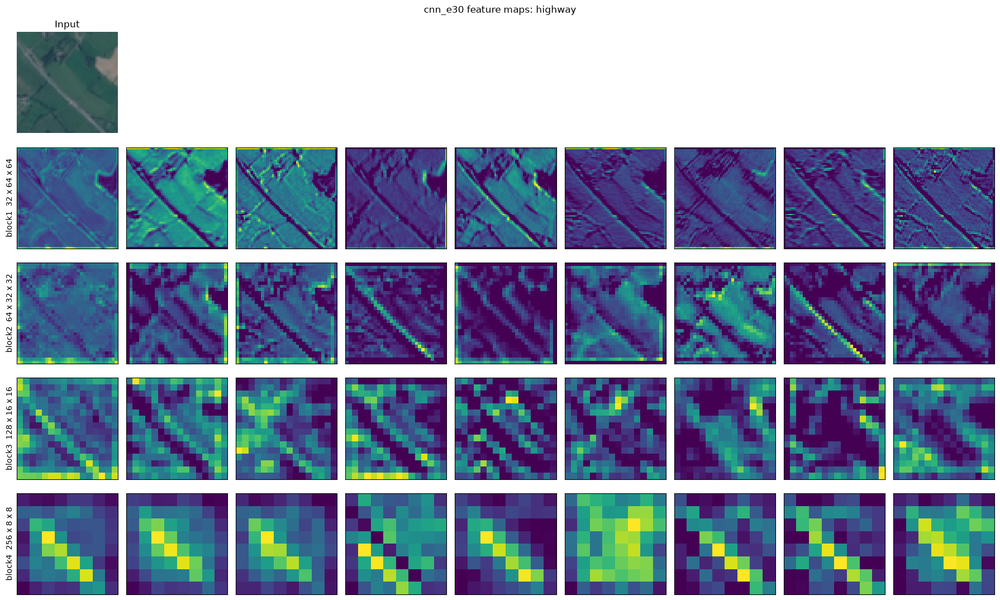

In [8]:
show("feature_maps_cnn_e30_highway.png", width=1000)

ResNet18:

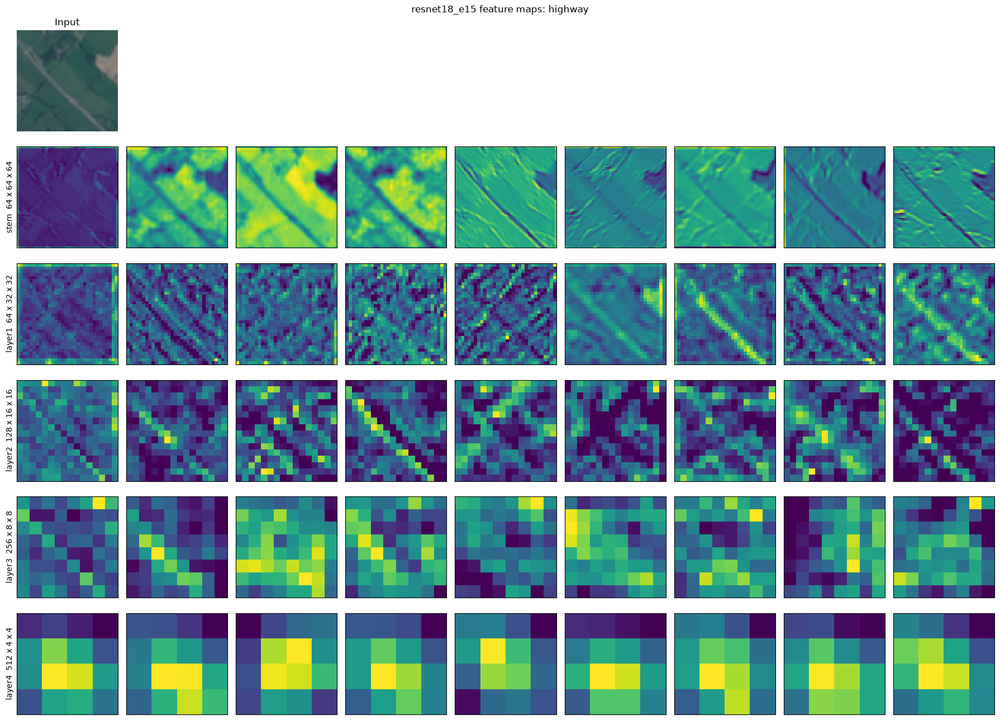

In [9]:
show("feature_maps_resnet18_e15_highway.png", width=1000)

**SimpleCNN.** In the first blocks the road appears as a thin diagonal line, bright in some channels and dark in others, together with the field boundaries. At 8 x 8 resolution (block 4) many channels still show a diagonal band from the upper left to the lower right, so the layout of the road survives up to the last convolutional block.

**ResNet18.** The stem has two kinds of channels: smooth ones that separate the fields (bright) from the road (dark), and edge-like ones that trace the road. The road is still visible as diagonal lines in layer 1 and layer 2 (32 x 32 and 16 x 16). At layer 3 (8 x 8) it is hard to read, and layer 4 (4 x 4) shows a bright blob near the center with dark corners.

### 3.2 Forest patch

SimpleCNN:

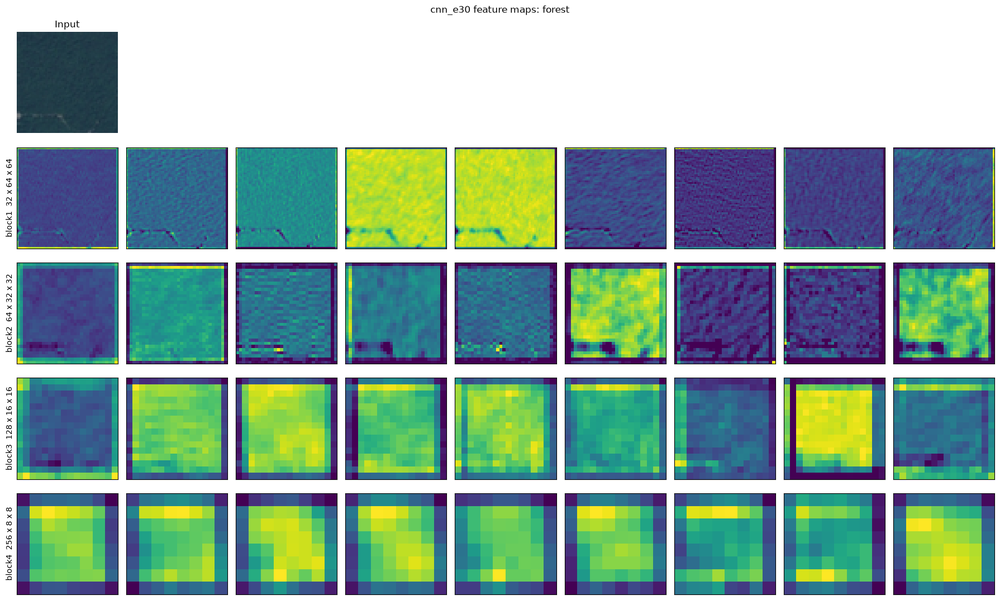

In [10]:
show("feature_maps_cnn_e30_forest.png", width=1000)

ResNet18:

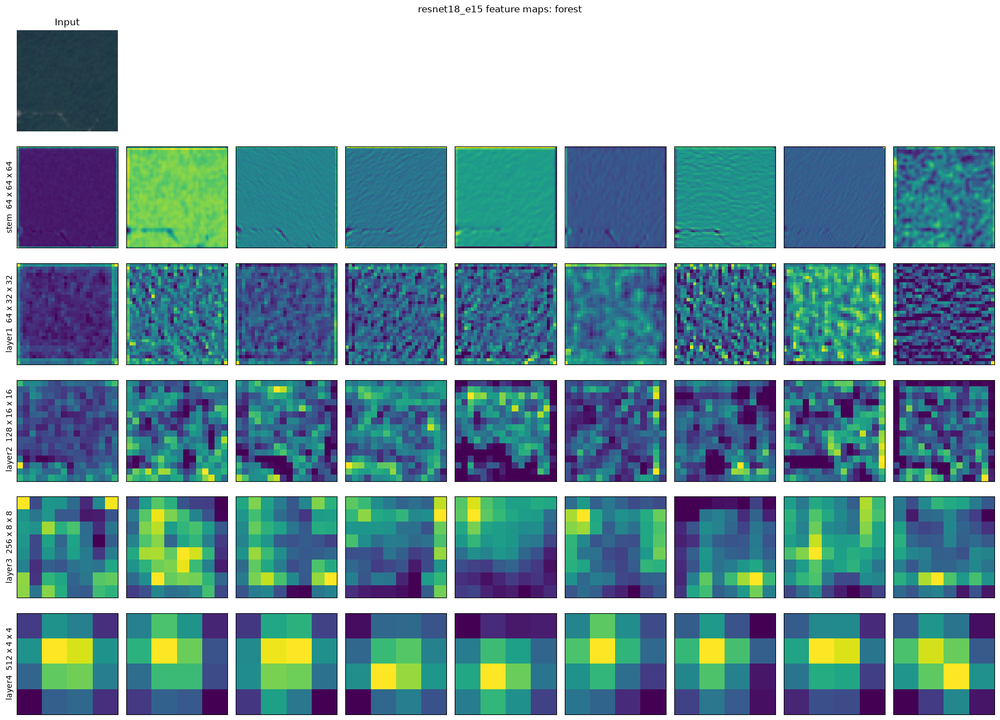

In [11]:
show("feature_maps_resnet18_e15_forest.png", width=1000)

This patch is mostly uniform texture. In the first blocks the canopy appears as a fine-grained texture, two of the displayed SimpleCNN block 1 channels respond over the whole patch, and the faint track at the bottom is visible in some channels. In the deeper blocks the activations become nearly uniform over the patch, so the evidence for `Forest` looks like dense uniform texture everywhere rather than a located object. Both models end with high activations in the center and low values at the border.

### 3.3 River patch misclassified by SimpleCNN

This `River` patch (a narrow dark channel crossing fields) is predicted as `AnnualCrop` by SimpleCNN and correctly by ResNet18.

SimpleCNN:

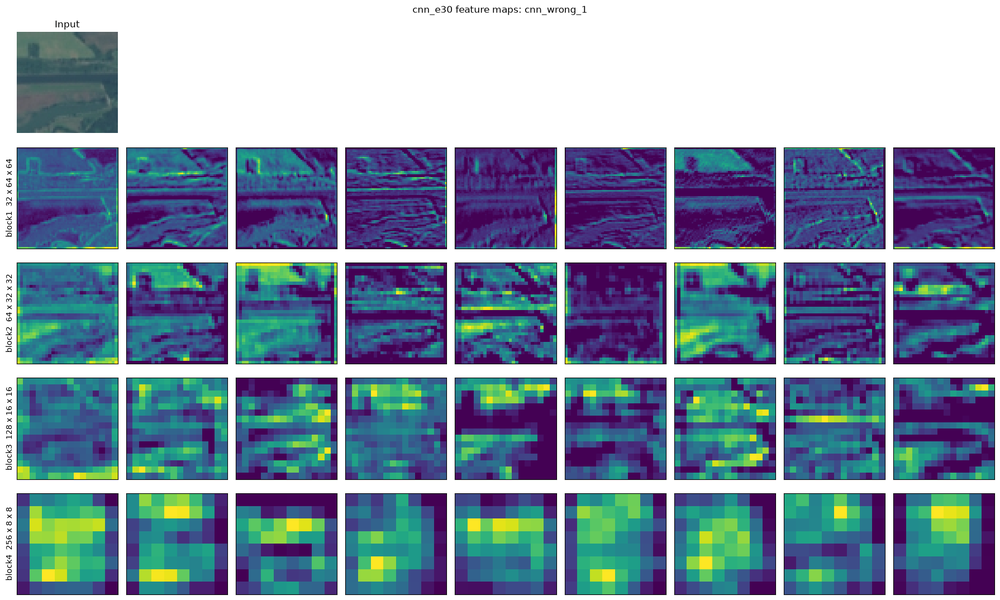

In [12]:
show("feature_maps_cnn_e30_cnn_wrong_1.png", width=1000)

ResNet18:

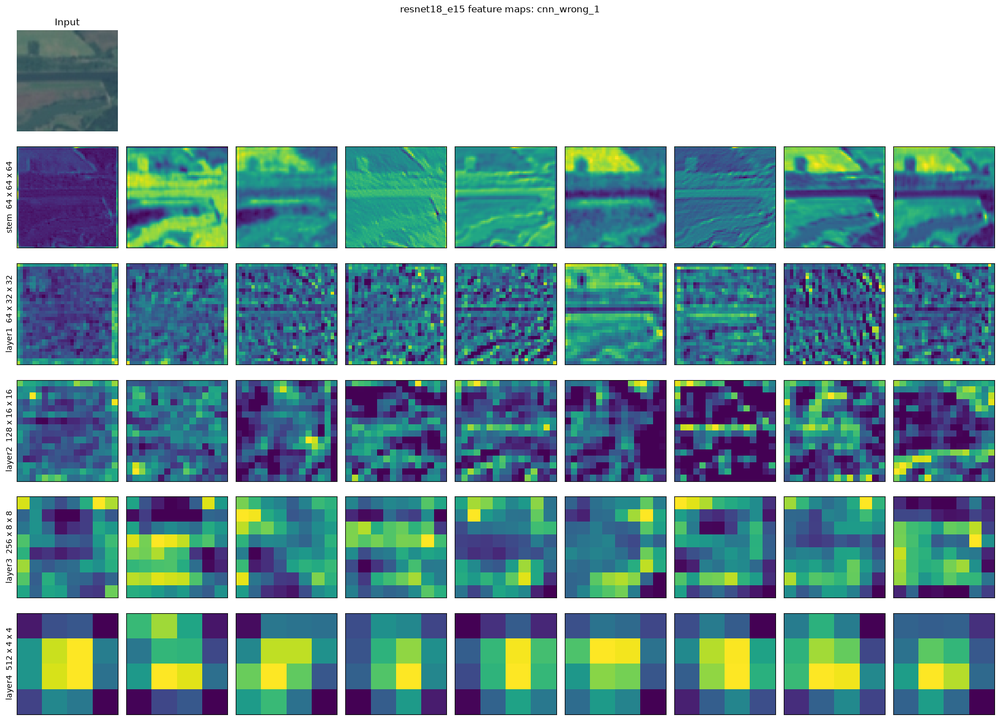

In [13]:
show("feature_maps_resnet18_e15_cnn_wrong_1.png", width=1000)

Both models show the channel as a horizontal dark band in the early layers, and horizontal stripes still appear in block 3 (SimpleCNN) and in layer 2 (ResNet18). In the last SimpleCNN block the maps are blobs without a clear horizontal band. This is consistent with the channel being a small part of a patch dominated by fields, but feature maps cannot show why a decision was wrong, so this is only a hint.

## 4. Observations and limitations

**What the figures show**

- Both models detect boundaries in the early layers (the road, field borders and the channel), even though the SimpleCNN first-layer filters do not look like edge detectors.
- SimpleCNN keeps the diagonal geometry of the road up to its last block (8 x 8). In ResNet18 the road is readable up to layer 2, while the last two stages are coarse.
- For `Forest`, the deep activations are nearly uniform over the patch, which fits a classification based on texture rather than on objects.
- ResNet18 keeps most of its ImageNet first-layer filters, with a few larger changes.

**Limits**

- The 4 x 4 maps of the last ResNet18 stage show almost the same pattern in all three patches (high in the center, low in the corners), so they carry little spatial information. This is why Grad-CAM is not used here: at these resolutions a heat map would be too coarse to interpret.
- Zero padding creates bright or dark frames at the borders of many maps, mostly in the deeper SimpleCNN blocks and as thin lines at the edges in block 1. These are edge effects, not image content.
- The eight displayed channels are chosen by mean activation for each patch, so they are not a random sample of the layer, and each map is normalized on its own.
- Only a few patches were inspected. A feature map shows what a layer responds to, not why the model chose a class.
- The weights of the untrained SimpleCNN were not saved, so its first-layer filters cannot be compared with their initial state.

**Next step:** these visualizations use EuroSAT RGB patches. The next step in the project is a custom dataset from Sentinel-2 imagery and Hansen Global Forest Change labels (see the roadmap in the README).